# 2D XRD Integration and Rietveld Refinement of FCC Nickel (`Ni`)

This Jupyter notebook documents the end-to-end processing of a 2D synchrotron X-ray diffraction (XRD) area-detector image (`Ni.tiff`) into a 1D diffraction profile and subsequent structural **Rietveld refinement** using **`easyXRD`** (powered by **pyFAI**, **FabIO**, and **GSAS-II**), following the workflow conventions in [`easyXRD_examples`](https://github.com/MehmetTopsakal/easyXRD_examples).

### Input Files
* **`Ni.tiff`**: Raw 2D diffraction image collected on a Dexela 2923 area detector ($3888 \times 3072$ pixels, $75\,\mu\text{m}$ pixel pitch).
* **`_calibration.poni`**: `pyFAI` geometric calibration file ($\lambda = 0.1799\,\text{\AA}$, sample-to-detector distance $D \approx 0.5995\,\text{m}$).
* **`_mask.edf`**: Pixel mask excluding the direct-beam stop, support arm shadow, and defective detector pixels.
* **`Ni.cif`**: Reference crystal structure for face-centered cubic (FCC) Nickel ($Fm\bar{3}m$, space group #225).
* **`_instrument_parameters.gpx`**: Pre-calibrated GSAS-II project file ($\text{LaB}_6$ standard) providing instrumental peak-profile parameters ($U, V, W, X, Y, Z, SH/L, \text{Zero}$).

### Table of Contents
1. [Environment Setup & Library Configuration](#setup)
2. [Inspect Raw 2D Detector Image, Pixel Mask & Calibration Files](#inspect-inputs)
3. [2D-to-1D Azimuthal Integration with pyFAI (`load_xrd_data`)](#integration)
4. [Crystal Structure Loading & Phase Matching (`load_phases`)](#phase-matching)
5. [Initialize GSAS-II Refiner with Calibrated Instrument Parameters (`setup_gsas2_refiner`)](#setup-refiner)
6. [Preliminary Profile Fitting (Le Bail Extraction)](#lebail-refinement)
   - Chebyshev Polynomial Background
   - Unit Cell Lattice Parameter
   - Microstructural Broadening (Crystallite Size & Microstrain)
7. [Structural Rietveld Refinement](#rietveld-refinement)
   - Transition from Le Bail to Rietveld (`set_LeBail(to=False)`)
   - Crystallographic Texture / Preferred Orientation (Spherical Harmonics)
   - Atomic Displacement / Thermal Parameter ($U_{\text{iso}}$)
8. [Final Multi-Parameter Polishing & Visualization](#final-polishing)
9. [Refinement Diagnostics, Physical Summary & Exporting Deliverables](#diagnostics-export)


<a id="setup"></a>
## 1. Environment Setup & Library Configuration

We begin by importing `easyxrd`, `pyFAI`, `fabio`, and `matplotlib`, configuring clean inline plotting (`figure.constrained_layout.use = True`), and verifying our software versions and working directory.


In [1]:
import os
import sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import fabio
import pyFAI
import GSASII.GSASIIscriptable as G2sc
import easyxrd
from easyxrd.core import exrd

%matplotlib inline
plt.rcParams["figure.constrained_layout.use"] = True
pyFAI.use_opencl = False

work_dir = Path("/home/mt/temp/1_Mo/Gemin-4-Argon-High").resolve()
if Path.cwd() != work_dir and work_dir.is_dir():
    os.chdir(work_dir)

print(f"Working directory: {Path.cwd()}")
easyxrd.show_config()

GSAS-II binaries co-located with GSAS-II: /home/mt/mpixi/.pixi/envs/default/lib/python3.14/site-packages/GSASII
4 values read from /home/mt/.GSASII/config.ini


Working directory: /home/mt/temp/1_Mo/Gemin-4-Argon-High
easyXRD environment and configurations
Platform            : Linux-7.1.5-76070105-generic-x86_64-with-glibc2.39
python              : 3.14.8
executable          : /home/mt/mpixi/.pixi/envs/default/bin/python
easyxrd             : 2026.10.20.post2
pyFAI               : 2026.9.0
fabio               : 2026.6.0
numpy               : 2.5.4
scipy               : 1.18.1
pandas              : 3.0.6
pymatgen            : 2026.9.24
GSAS-II             : 2.0.0
GSASII_module       : /home/mt/mpixi/.pixi/envs/default/lib/python3.14/site-packages/GSASII/GSASIIscriptable.py
easyxrd_scratch_path: /home/mt/.easyxrd_scratch
gsasii_lib_path     : /home/mt/mpixi/.pixi/envs/default/lib/python3.14/site-packages/GSASII
mp_api_key          : dHgNQ......
----------------------------------------



<a id="inspect-inputs"></a>
## 2. Inspect Raw 2D Detector Image, Pixel Mask & Calibration Files

Before azimuthal integration, we inspect:
1. **`Ni.tiff`**: Concentric Debye–Scherrer diffraction rings of polycrystalline FCC Ni on the 2D detector plane, together with the central beamstop and horizontal support arm shadow.
2. **`_mask.edf`**: Binary pixel mask (`1` = masked, `0` = active) created to exclude the beamstop shadow and hot/dead pixels during integration.
3. **`_calibration.poni` & `_instrument_parameters.gpx`**: Geometric detector calibration and GSAS-II instrumental broadening parameters determined from a $\text{LaB}_6$ standard under identical beamline conditions.


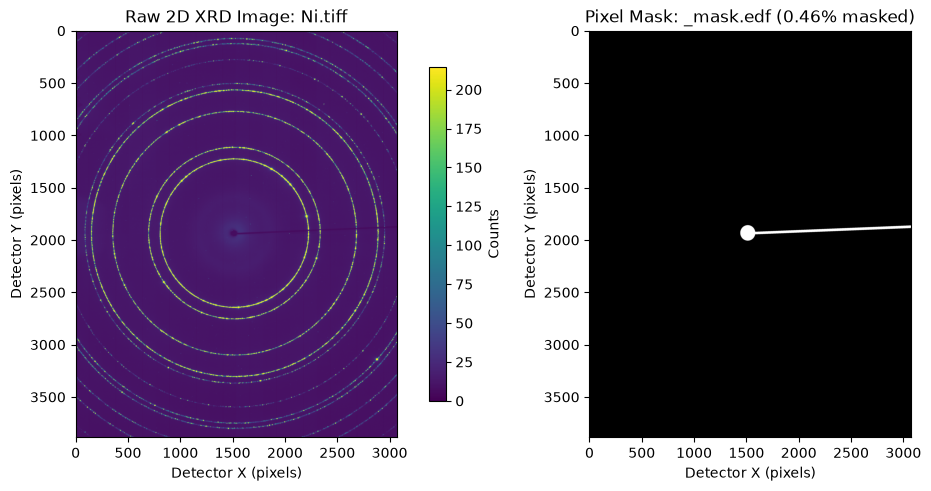

In [2]:
# Load raw 2D detector TIFF image and EDF bad-pixel/beamstop mask
raw_img = fabio.open("Ni.tiff").data
mask_img = fabio.open("_mask.edf").data

fig, axes = plt.subplots(1, 2, figsize=(10, 4.8))

im0 = axes[0].imshow(raw_img, vmin=0, vmax=np.percentile(raw_img, 99), cmap="viridis")
axes[0].set_title("Raw 2D XRD Image: Ni.tiff")
axes[0].set_xlabel("Detector X (pixels)")
axes[0].set_ylabel("Detector Y (pixels)")
fig.colorbar(im0, ax=axes[0], shrink=0.82, label="Counts")

im1 = axes[1].imshow(mask_img, cmap="gray")
axes[1].set_title(f"Pixel Mask: _mask.edf ({100 * np.mean(mask_img != 0):.2f}% masked)")
axes[1].set_xlabel("Detector X (pixels)")
axes[1].set_ylabel("Detector Y (pixels)")
plt.show()

In [3]:
# Inspect pyFAI calibration geometry (.poni) and pre-calibrated GSAS-II instrument parameters (.gpx)
ai_calib = pyFAI.load("_calibration.poni")
print("=== pyFAI Calibration (_calibration.poni) ===")
print(ai_calib)

gpx_inst = G2sc.G2Project(gpxfile="_instrument_parameters.gpx")
hist_inst = gpx_inst.histograms()[0]
inst_params = hist_inst["Instrument Parameters"][0]

print("\n=== GSAS-II Instrument Parameters (_instrument_parameters.gpx) ===")
for key in ["Type", "Lam", "Zero", "Polariz.", "Azimuth", "U", "V", "W", "X", "Y", "Z", "SH/L"]:
    if key in inst_params:
        print(f"  {key:<10}: {inst_params[key][1]}")

=== pyFAI Calibration (_calibration.poni) ===
Detector Dexela 2923	 PixelSize= 75µm, 75µm	 BottomRight (3)
Wavelength= 0.179900 Å
SampleDetDist= 5.994972e-01 m	PONI= 1.406570e-01, 9.934597e-02 m	rot1=-0.023867  rot2=0.007321  rot3=0.000000 rad
DirectBeamDist= 599.684 mm	Center: x=1515.422, y=1933.965 pix	Tilt= 1.430° tiltPlanRotation= 17.056° λ= 0.180Å

=== GSAS-II Instrument Parameters (_instrument_parameters.gpx) ===
  Type      : PXC
  Lam       : 0.1799
  Zero      : 0.0
  Polariz.  : 0.0
  Azimuth   : 0.0
  U         : -29.429568076072545
  V         : 13.79133563712429
  W         : 0.8708911222388265
  X         : 0.07517037719725798
  Y         : -1.0844016461422603
  Z         : 0.040769097713890166
  SH/L      : 0.005540666212782422


<a id="integration"></a>
## 3. 2D-to-1D Azimuthal Integration with pyFAI (`load_xrd_data`)

Using `sample.load_xrd_data(...)`, `easyXRD` performs solid-angle-corrected 2D azimuthal "caking" (`i2d`, azimuthal angle $\chi$ vs. scattering vector $q = \frac{4\pi \sin\theta}{\lambda}$) via `pyFAI`, applies `_mask.edf`, and averages along the azimuthal dimension to obtain the 1D powder diffraction profile (`i1d`).

First, we integrate across the entire detector range to examine the full data coverage and identify any low-$q$ beamstop or high-$q$ detector-corner artifacts.


Full integrated q-range: [0.304, 10.472] Å⁻¹ (10169 points)


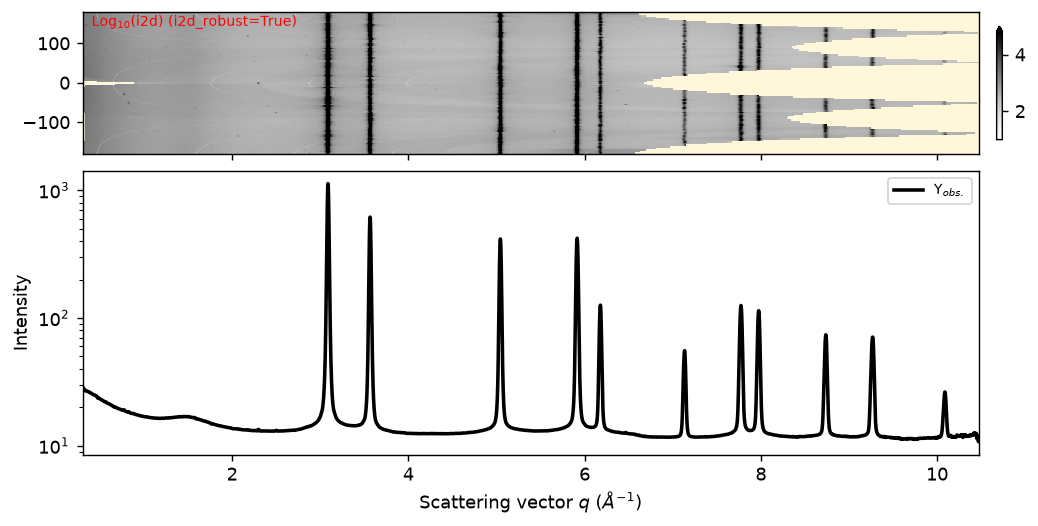

In [4]:
# Initialize easyXRD analysis object and integrate full 2D image
sample = exrd()
sample.load_xrd_data(
    from_tiff_file="Ni.tiff",
    poni_file="_calibration.poni",
    mask_file="_mask.edf",
    plot=True,
)

print(
    f"Full integrated q-range: [{float(sample.ds.i1d.radial.min()):.3f}, "
    f"{float(sample.ds.i1d.radial.max()):.3f}] Å⁻¹ ({len(sample.ds.i1d)} points)"
)

### Selecting the Optimal Radial Range (`radial_range`) & Exporting the 1D Profile

Inspecting the caked 2D image (`i2d`) and 1D profile (`i1d`) above reveals three key experimental features:
1. **Low-$q$ region ($q < 1.0\,\text{\AA}^{-1}$)**: Affected by the central beamstop shadow and small-angle air-scattering tail (followed by a smooth diffuse background hump from the sample holder/Kapton near $q \approx 1.48\,\text{\AA}^{-1}$).
2. **High-$q$ detector corners ($q > 10.25\,\text{\AA}^{-1}$)**: Only the extreme corners of the rectangular detector contribute pixels (large yellow unmeasured regions in `i2d`), increasing statistical noise beyond the `(4, 4, 0)` reflection at $q \approx 10.09\,\text{\AA}^{-1}$.
3. **Azimuthal intensity modulation**: Along the vertical Bragg lines in `i2d`, intensity varies subtly with azimuthal angle $\chi$, indicating mild crystallographic texture / coarse grain statistics that we will explicitly model during Rietveld refinement.

We therefore restrict `radial_range=[1.0, 10.25]` $\text{\AA}^{-1}$ to retain all 11 observed Bragg reflections cleanly while excluding the beamstop shadow and extreme corner noise, and export the resulting 1D profile to text files (`Ni_1D_tth.xy` and `Ni_1D_q.xy`).


Exported 1D profiles: Ni_1D_tth.xy (2θ, I) and Ni_1D_q.xy (q, I)


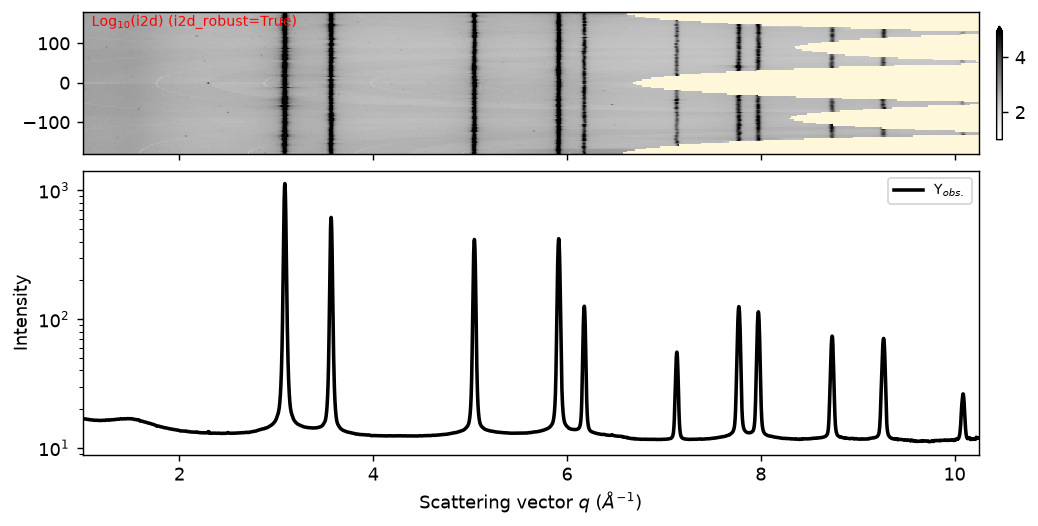

In [5]:
# Re-integrate within clean active q-range [1.0, 10.25] Å⁻¹
sample = exrd()
sample.load_xrd_data(
    from_tiff_file="Ni.tiff",
    poni_file="_calibration.poni",
    mask_file="_mask.edf",
    radial_range=[1.0, 10.25],
    plot=True,
)

# Export integrated 1D XRD profiles (2θ vs. Intensity and q vs. Intensity)
sample.export_i1d_to(to="Ni_1D_tth.xy", mode="xy", header=True)
sample.export_i1d_to(to="Ni_1D_q.xy", mode="qxy", header=True)
print("Exported 1D profiles: Ni_1D_tth.xy (2θ, I) and Ni_1D_q.xy (q, I)")

<a id="phase-matching"></a>
## 4. Crystal Structure Loading & Phase Matching (`load_phases`)

Next, we load `Ni.cif` ($Fm\bar{3}m$, space group #225, $Z = 4$, Ni at Wyckoff $4a$ site $(0, 0, 0)$, DFT-calculated cubic lattice constant $a = 3.52558\,\text{\AA}$) via `sample.load_phases(...)` and compare the simulated Bragg reflection stems against our experimental 1D profile.


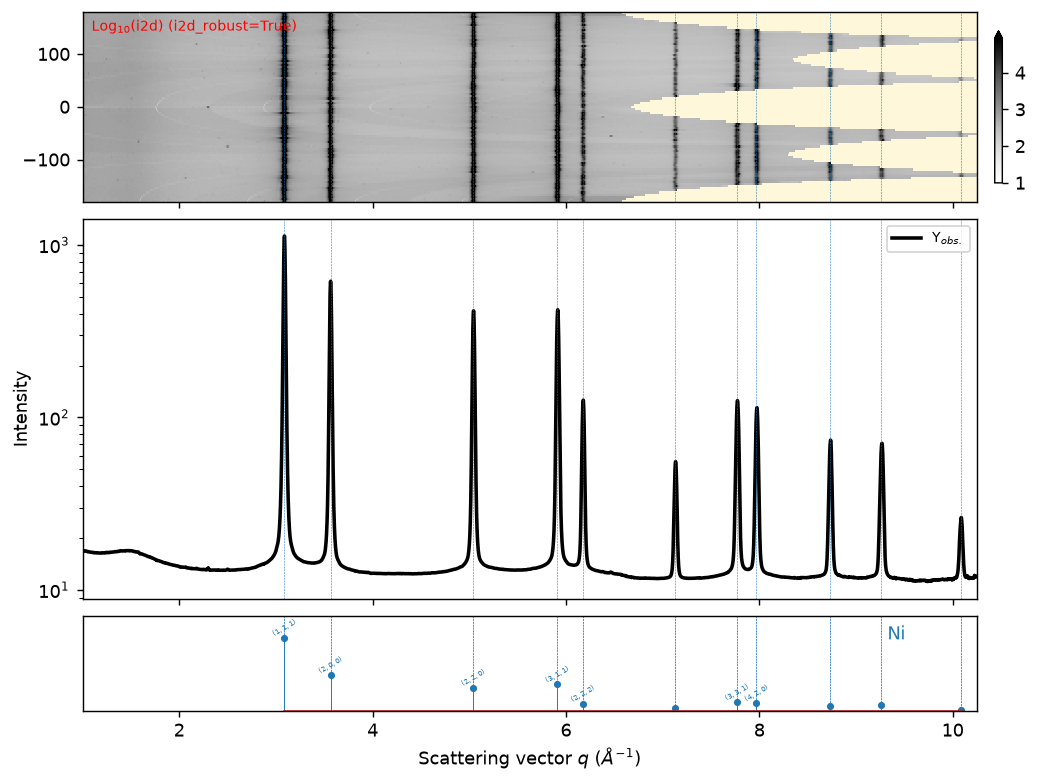

In [6]:
phases = [
    {"cif": "Ni.cif", "label": "Ni"},
]
sample.load_phases(phases, plot=True)

Every observed diffraction peak across $q \in [1.0, 10.25]\,\text{\AA}^{-1}$ matches an allowed FCC Nickel reflection:
`(111)`, `(200)`, `(220)`, `(311)`, `(222)`, `(400)`, `(331)`, `(420)`, `(422)`, `(511)/(333)`, and `(440)`, confirming single-phase purity with no unindexed impurity peaks. A slight offset at higher $q$ is expected because the DFT-relaxed lattice parameter in `Ni.cif` ($3.52558\,\text{\AA}$) is slightly larger than the experimental room-temperature lattice constant.


<a id="setup-refiner"></a>
## 5. Initialize GSAS-II Refiner with Calibrated Instrument Parameters (`setup_gsas2_refiner`)

We initialize the GSAS-II refinement engine via `sample.setup_gsas2_refiner(...)` using `instprm_from_gpx="_instrument_parameters.gpx"`.

Because instrumental broadening ($U, V, W, X, Y, Z, SH/L$) was already calibrated on a $\text{LaB}_6$ standard in `_instrument_parameters.gpx`, we hold the instrumental profile fixed during sample refinement. This prevents parameter correlation and ensures that any excess peak broadening in `Ni.tiff` is accurately attributed to intrinsic sample microstructure (crystallite domain size and lattice microstrain).


 ✅--1st refinement with LeBail is completed. Rwp/GoF is 26.458/1.242


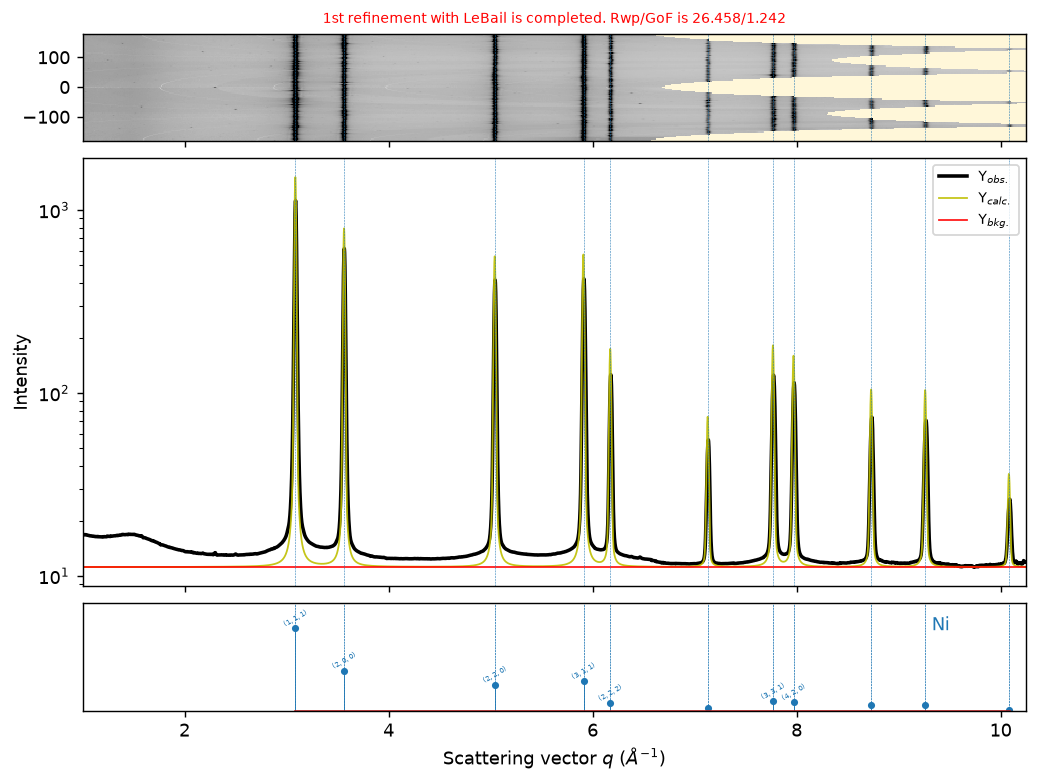

In [7]:
sample.setup_gsas2_refiner(
    instprm_from_gpx="_instrument_parameters.gpx",
    do_1st_refinement=True,
    plot=True,
)

<a id="lebail-refinement"></a>
## 6. Preliminary Profile Fitting (Le Bail Extraction)

Following the recommended progressive refinement protocol in `easyXRD_examples`, we first optimize profile and lattice parameters in **Le Bail mode** (`LeBail=True`), where reflection intensities are extracted freely without structural constraints so that background, peak positions, and peak shapes converge cleanly without false minima:

1. **Background Modeling (`refine_background`)**: Orthogonal Chebyshev polynomial series
   $$Y_{\text{bkg}}(2\theta) = \sum_{m=0}^{N-1} C_m\,T_m(x)$$
   escalated from $N = 5$ to $N = 10$ coefficients to capture diffuse scattering including the low-$q$ hump near $q \approx 1.48\,\text{\AA}^{-1}$.
2. **Unit Cell Refinement (`refine_cell_parameters`)**: Adjusts the cubic lattice constant $a$ of $Fm\bar{3}m$ Ni to align all 11 Bragg peak positions.
3. **Microstructural Broadening (`refine_size_broadening`, `refine_strain_broadening`)**: Models isotropic crystallite domain size broadening ($\propto 1/\cos\theta$) and isotropic microstrain broadening ($\propto \tan\theta$), followed by unit cell re-alignment.


 ✅--Background with 5 coeffs is refined. Rwp/GoF is now 21.121/0.991 (was 26.458(-20.17%)/1.242(-20.15%✨))


 ✅--Background with 10 coeffs is refined. Rwp/GoF is now 20.915/0.982 (was 21.121(-0.97%)/0.991(-0.95%❗))


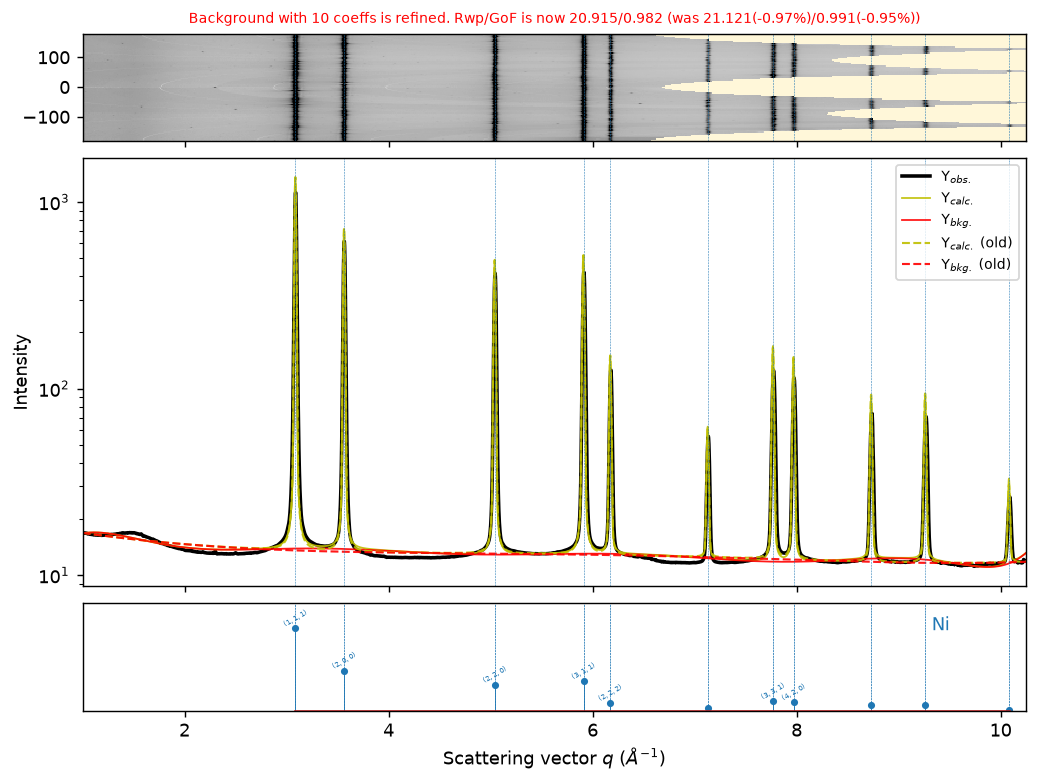

In [8]:
# 6.1 Refine Chebyshev polynomial background (gradually increasing from 5 to 10 terms)
sample.refine_background(num_coeffs=5, plot=False)
sample.refine_background(num_coeffs=10, plot=True)

 ✅--Cell parameters are refined. Rwp/GoF is now 13.295/0.624 (was 20.915(-36.43%)/0.982(-36.46%✨))

Ni-phase

Fm-3m (cubic)

     refined (old)                     
 a=3.52336 (3.52558) 
 b=3.52336 (3.52558) 
 c=3.52336 (3.52558)                     
 \alpha=90.00 (90.00) 
 \beta=90.00 (90.00) 
 \gamma=90.00 (90.00) 



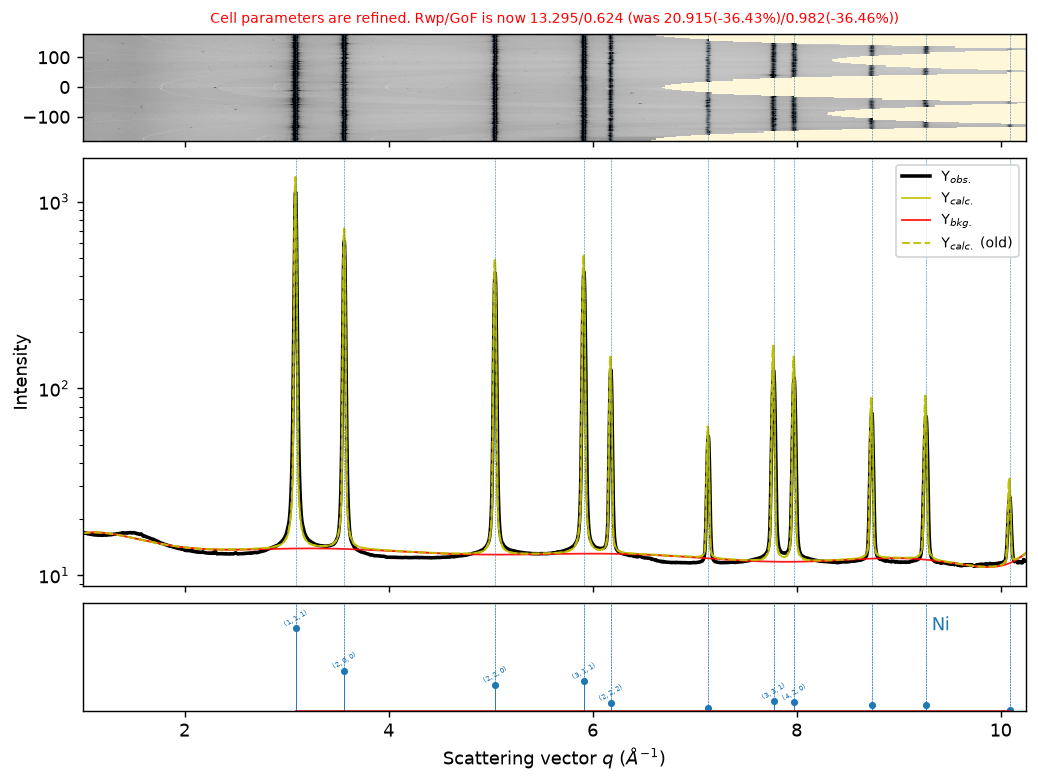

In [9]:
# 6.2 Refine cubic unit cell parameter (a = b = c)
sample.refine_cell_parameters(plot=True, report=True)

 ✅--Size broadening of all phases are refined. Rwp/GoF is now 9.250/0.434 (was 13.295(-30.43%)/0.624(-30.43%✨))

Ni-phase

Fm-3m (cubic)

     refined (old)                     
 type=isotropic (isotropic) 
 size_0=0.13210 (1.00000) 
 size_1=1.00000 (1.00000) 
 size_2=1.00000 (1.00000) 



 ✅--Strain broadening of all phases are refined. Rwp/GoF is now 9.240/0.434 (was 9.250(-0.11%)/0.434(-0.11%❗))

Ni-phase

Fm-3m (cubic)

     refined (old)                     
 type=isotropic (isotropic) 
 mustrain_0=1072.23550 (1000.00000) 
 mustrain_1=1000.00000 (1000.00000) 
 mustrain_2=1.00000 (1.00000) 



 ✅--Cell parameters are refined. Rwp/GoF is now 6.977/0.327 (was 9.240(-24.49%)/0.434(-24.49%✨))

Ni-phase

Fm-3m (cubic)

     refined (old)                     
 a=3.52243 (3.52336) 
 b=3.52243 (3.52336) 
 c=3.52243 (3.52336)                     
 \alpha=90.00 (90.00) 
 \beta=90.00 (90.00) 
 \gamma=90.00 (90.00) 



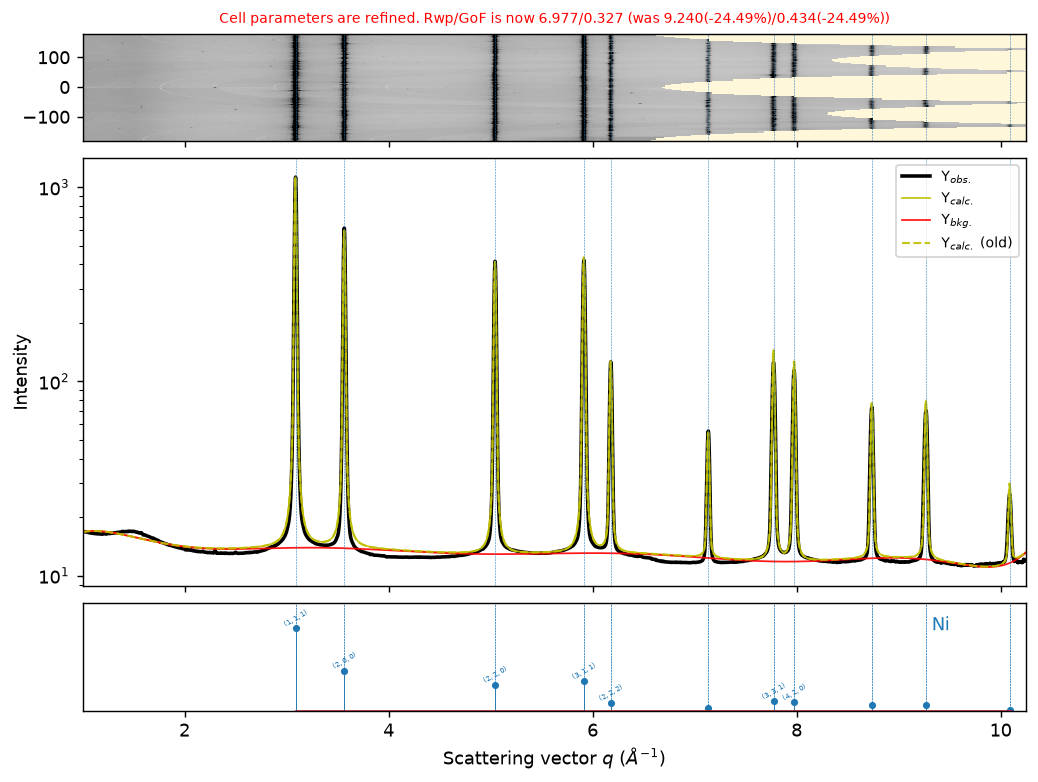

In [10]:
# 6.3 Refine isotropic crystallite size and microstrain broadening, then re-align unit cell
sample.refine_size_broadening(phase_ind="all", type="isotropic", plot=False, report=True)
sample.refine_strain_broadening(phase_ind="all", type="isotropic", plot=False, report=True)
sample.refine_cell_parameters(plot=True, report=True)

<a id="rietveld-refinement"></a>
## 7. Structural Rietveld Refinement

With background, unit cell dimensions, and peak shapes accurately established ($R_{wp} = 6.977\%$ in Le Bail mode), we now transition to full **structural Rietveld refinement** via `sample.set_LeBail(to=False, refine=True, plot=True)`.

In Rietveld mode, integrated reflection intensities are calculated directly from the crystal structure factor $F_{hkl}$:

$$I_{hkl} \propto |F_{hkl}|^2 = \left| \sum_j f_j \cdot \text{occ}_j \cdot \exp\!\left( -8\pi^2 U_{\text{iso}, j} \frac{\sin^2\theta}{\lambda^2} \right) \cdot \exp\!\big(2\pi i (h x_j + k y_j + l z_j)\big) \right|^2$$


 ✅--After setting LeBail refinement to False, Rwp/GoF is now 15.247/0.716 (was 6.977(118.52%)/0.327(118.50%❗))


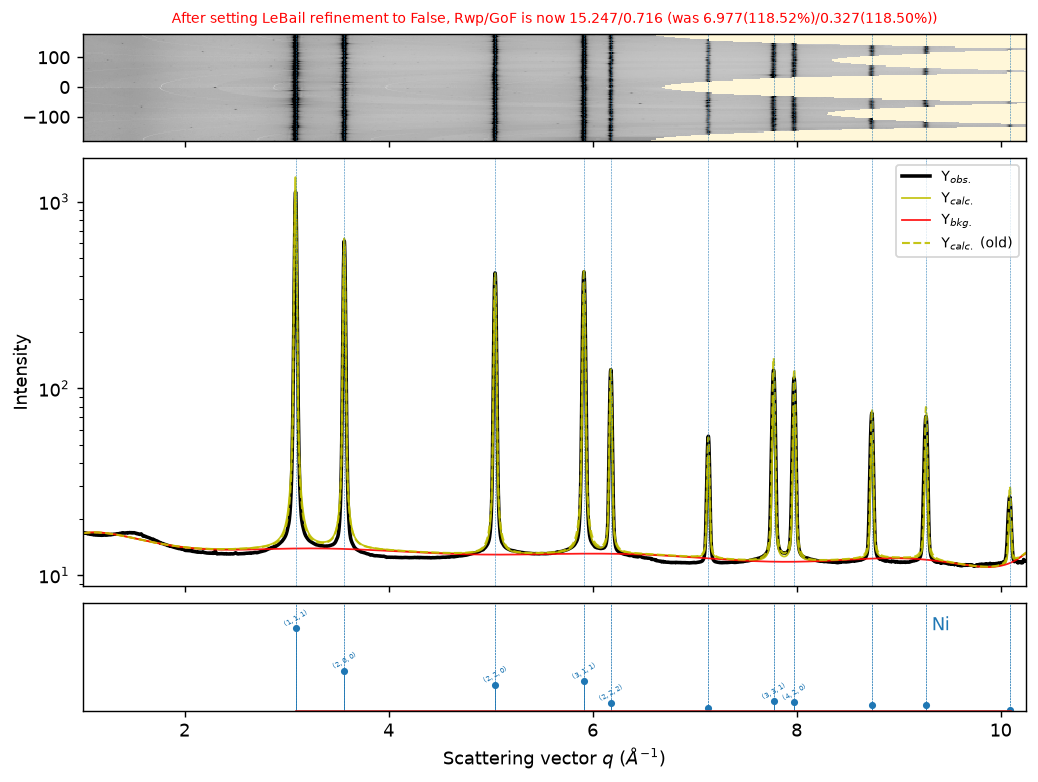

In [11]:
# 7.1 Switch from structure-free Le Bail extraction to structural Rietveld refinement
sample.set_LeBail(to=False, refine=True, plot=True)

### Modeling Preferred Orientation (Texture) and Atomic Thermal Motion ($U_{\text{iso}}$)

Upon enabling structural Rietveld calculation, $R_{wp}$ rises from $6.977\%$ to $15.247\%$ for two physically transparent reasons:
1. **Crystallographic Preferred Orientation (Texture)**: As observed in the 2D `i2d` cake, non-uniform grain orientation distribution modulates relative `(hkl)` intensities (e.g., `(111)` and `(200)` vs. `(220)` and `(311)`). Because Nickel is cubic ($m\bar{3}m$ Laue symmetry), the $L = 2$ spherical harmonic order contains zero symmetry-allowed terms, while $L = 4, 6, 8$ introduce the cubic spherical harmonics $C(4,1)$, $C(6,1)$, and $C(8,1)$. We therefore refine preferred orientation with `harmonics_order=8`.
2. **Isotropic Atomic Displacement Parameter ($U_{\text{iso}}$)**: When importing `Ni.cif`, GSAS-II initializes `Ni0` with a generic default $U_{\text{iso}} = 0.010\,\text{\AA}^2$, which is more than twice the room-temperature Debye–Waller factor of metallic Ni and excessively damps high-$q$ calculated intensities. Refining `refinement_flags="U"` on `Ni0` (`site_ind=0`) optimizes $U_{\text{iso}}$ to match the experimental high-$q$ intensity decay. *(Note: In $Fm\bar{3}m$, the `Ni0` fractional coordinates $(0, 0, 0)$ are fixed by special Wyckoff symmetry and require no coordinate refinement.)*


 ✅--Preferred orientation for Ni phase is refined. Rwp/GoF is now 9.712/0.456 (was 15.247(-36.30%)/0.716(-36.29%✨))


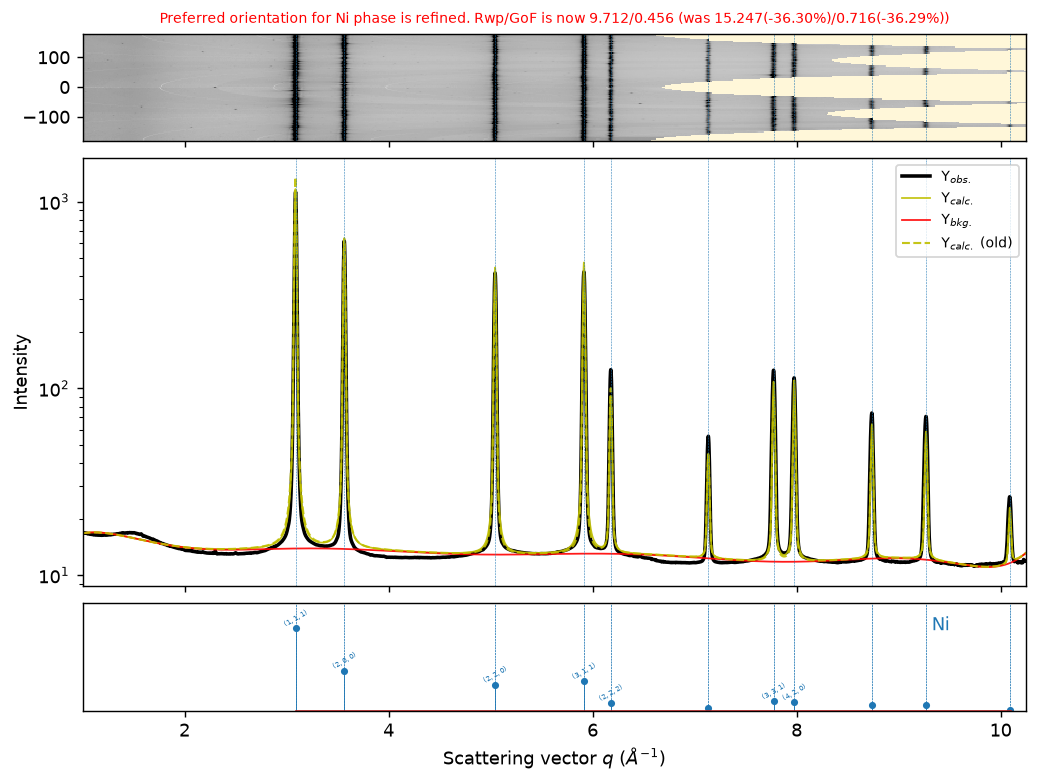

In [12]:
# 7.2 Refine preferred orientation using generalized spherical harmonics (order 8 for cubic m-3m)
sample.refine_preferred_orientation(phase_ind=0, harmonics_order=8, plot=True)

 ✅--U property of Ni0 site of Ni phase is refined. Rwp/GoF is now 8.684/0.408 (was 9.712(-10.58%)/0.456(-10.59%✨))


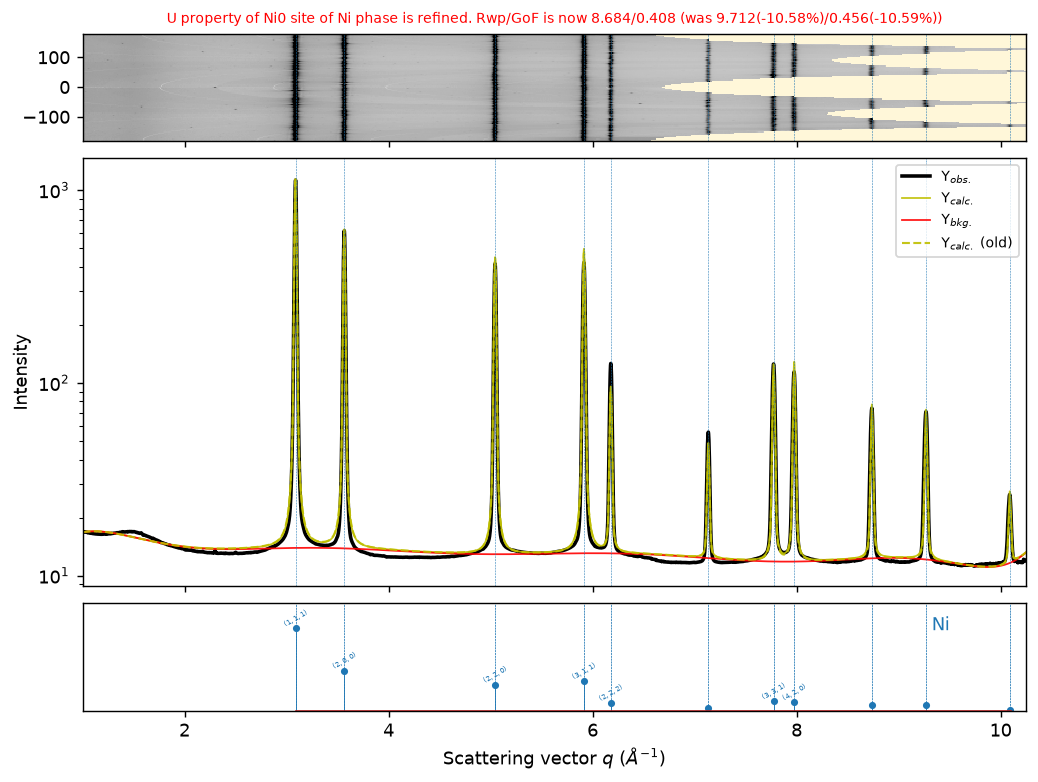

In [13]:
# 7.3 Refine isotropic thermal displacement parameter (Uiso) of the Ni0 (4a) site
sample.refine_site_property(phase_ind=0, site_ind=0, refinement_flags="U", plot=True)

<a id="final-polishing"></a>
## 8. Final Multi-Parameter Polishing & Visualization

Finally, we perform a polishing pass across background (`num_coeffs=15`), microstructure (size and microstrain), unit cell lattice constant, preferred orientation, and `Ni0` $U_{\text{iso}}$ so all coupled profile and structural parameters reach self-consistent convergence. We then visualize the final Rietveld fit on both **logarithmic** and **linear** intensity scales.


 ✅--Background with 15 coeffs is refined. Rwp/GoF is now 7.816/0.367 (was 8.684(-10.00%)/0.408(-9.93%))
 ✅--Size broadening of all phases are refined. Rwp/GoF is now 7.812/0.367 (was 7.816(-0.05%)/0.367(-0.13%❗))


 ✅--Strain broadening of all phases are refined. Rwp/GoF is now 7.803/0.366 (was 7.812(-0.12%)/0.367(-0.12%❗))


 ✅--Cell parameters are refined. Rwp/GoF is now 7.813/0.367 (was 7.803(0.12%)/0.366(0.12%❗))


 ✅--Preferred orientation for Ni phase is refined. Rwp/GoF is now 7.118/0.334 (was 7.813(-8.89%)/0.367(-8.88%))


 ✅--U property of Ni0 site of Ni phase is refined. Rwp/GoF is now 6.680/0.313 (was 7.118(-6.16%)/0.334(-6.17%))


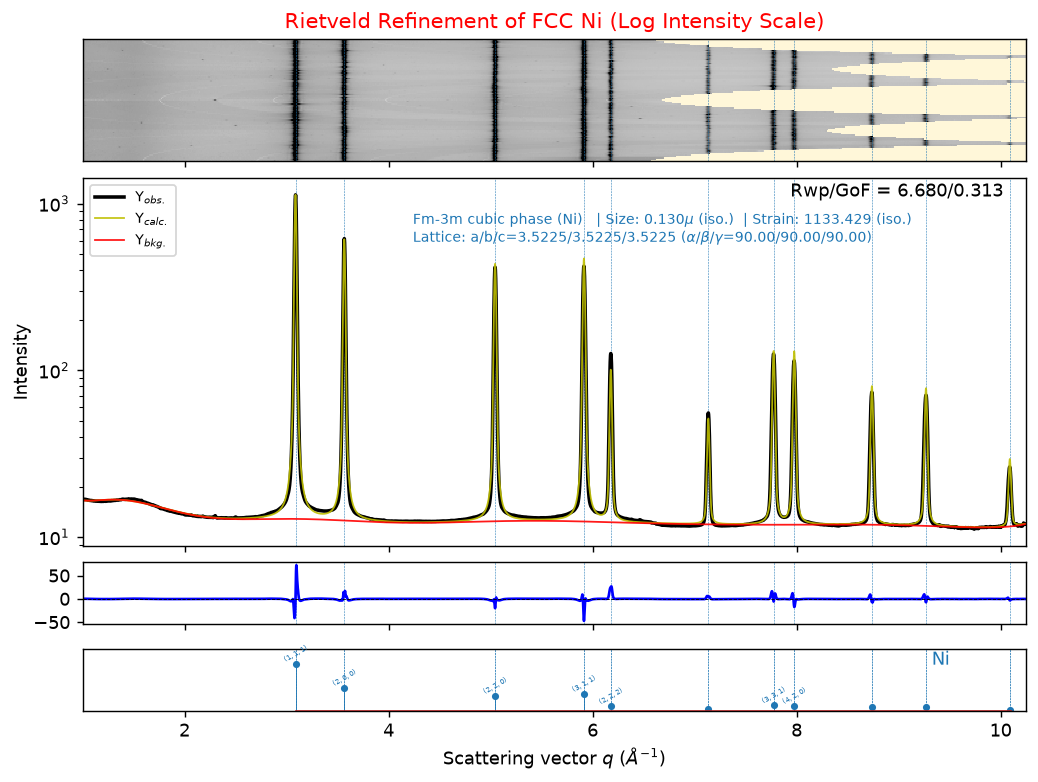

In [14]:
# Final self-consistent polishing pass
sample.refine_background(num_coeffs=15, plot=False)
sample.refine_size_broadening(phase_ind="all", type="isotropic", plot=False)
sample.refine_strain_broadening(phase_ind="all", type="isotropic", plot=False)
sample.refine_cell_parameters(plot=False)
sample.refine_preferred_orientation(phase_ind=0, harmonics_order=8, plot=False)
sample.refine_site_property(phase_ind=0, site_ind=0, refinement_flags="U", plot=False)

# Plot final Rietveld refinement (logarithmic intensity scale) and save high-resolution PDF
sample.plot(
    i1d_ylogscale=True,
    site_str_x=0.35,
    site_str_y=0.78,
    title="Rietveld Refinement of FCC Ni (Log Intensity Scale)",
    export_fig_as="Ni_Rietveld_plot.pdf",
)

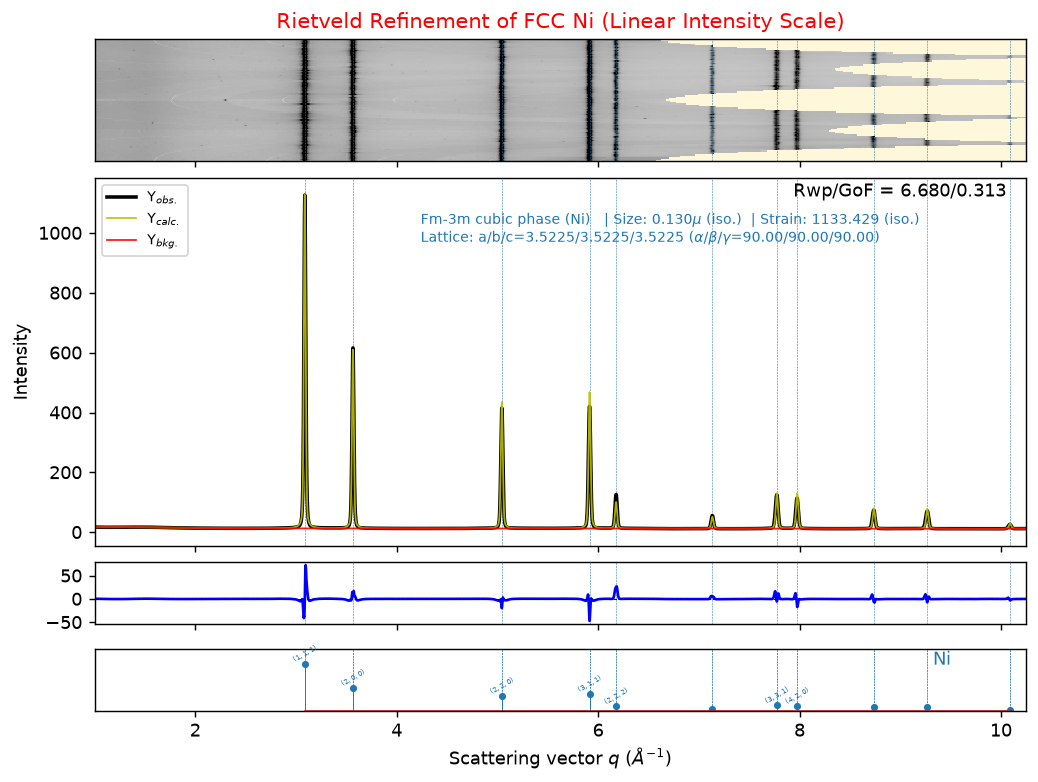

In [15]:
# Plot final Rietveld refinement on a linear intensity scale to inspect major peak heights and residuals
sample.plot(
    i1d_ylogscale=False,
    site_str_x=0.35,
    site_str_y=0.78,
    title="Rietveld Refinement of FCC Ni (Linear Intensity Scale)",
)

<a id="diagnostics-export"></a>
## 9. Refinement Diagnostics, Physical Summary & Exporting Deliverables

We evaluate the statistical figures of merit:

$$R_{\text{wp}} = \sqrt{ \frac{\sum_i w_i (y_i - y_{c,i})^2}{\sum_i w_i y_i^2} } \times 100\%, \qquad R_{\text{p}} = \frac{\sum_i |y_i - y_{c,i}|}{\sum_i y_i} \times 100\%, \qquad \text{GoF} = \sqrt{\chi^2}$$

extract all refined crystallographic, microstructural, thermal, and texture parameters, and export the final GSAS-II project (`Ni_refined.gpx`), refined crystal structure (`Ni_refined.cif`), and `easyXRD` NetCDF dataset (`Ni_refined.nc`).


In [16]:
# Compute unweighted profile residual Rp directly from Yobs and Ycalc
y_obs = sample.ds.i1d.values
y_calc = sample.ds.i1d_refined.values
rp_val = 100.0 * np.sum(np.abs(y_obs - y_calc)) / np.sum(y_obs)

# Extract refined crystallographic & atomic parameters from GSAS-II project and xarray Dataset
ni_phase = sample.gpx.phases()[0]
cell_list = ni_phase["General"]["Cell"]  # [refine_flag, a, b, c, alpha, beta, gamma, volume]
a_ref = cell_list[1]
vol_ref = cell_list[7]
density_ref = ni_phase["General"].get("Mass", 4 * 58.6934) / (0.602214076 * vol_ref)

atom_ni0 = ni_phase["Atoms"][0]
uiso_ref = atom_ni0[10]
biso_ref = 8.0 * (np.pi ** 2) * uiso_ref

pref_ori = sample.gpx["Phases"]["Ni"]["Histograms"]["PWDR data.xy"]["Pref.Ori."]
sh_coeffs = pref_ori[5]

print("==========================================================")
print("          FINAL RIETVELD REFINEMENT SUMMARY (Ni)          ")
print("==========================================================")
print(f"Convergence Status       : {sample.ds.attrs.get('converged', 'N/A')}")
print(f"Data Points (Nobs)       : {sample.ds.attrs.get('Nobs', len(y_obs))}")
print(f"q-Range Refined          : [{float(sample.ds.i1d.radial.min()):.3f}, {float(sample.ds.i1d.radial.max()):.3f}] Å⁻¹")
print(f"X-ray Wavelength (λ)     : {sample.ds.i1d.attrs['wavelength_in_angst']:.4f} Å")
print("----------------------------------------------------------")
print(f"Weighted Residual (Rwp)  : {sample.ds.attrs['Rwp']:.3f}%")
print(f"Unweighted Residual (Rp) : {rp_val:.3f}%")
print(f"Chi-Squared (χ²)         : {sample.ds.attrs['chisq']:.2f}")
print(f"Goodness of Fit (GoF)    : {sample.ds.attrs['GOF']:.3f}")
print("----------------------------------------------------------")
print(f"Space Group              : {sample.ds.attrs['PhaseInd_0_SpGrp'].strip()} ({sample.ds.attrs['PhaseInd_0_SGSys']})")
print(f"Initial CIF Lattice (a)  : 3.52558 Å")
print(f"Refined Lattice (a=b=c)  : {a_ref:.5f} Å")
print(f"Refined Unit Cell Volume : {vol_ref:.4f} Å³")
print(f"Calculated X-ray Density : {density_ref:.3f} g/cm³")
print(f"Ni0 Isotropic Uiso       : {uiso_ref:.5f} Å²  (Biso = {biso_ref:.3f} Å²)")
print(f"Isotropic Domain Size    : {sample.ds.attrs['PhaseInd_0_size_0']:.4f} µm")
print(f"Isotropic Microstrain    : {sample.ds.attrs['PhaseInd_0_mustrain_0']:.2f} (×10⁻⁶)")
print("Spherical Harmonics (L=8): " + ", ".join(f"{k} = {v:.4f}" for k, v in sh_coeffs.items()))
print("==========================================================")

# Export refined GSAS-II project (.gpx), refined CIF (.cif), and NetCDF dataset (.nc)
sample.export_gpx_to("Ni_refined.gpx")
sample.export_phases(export_to=".", export_extension="_refined.cif")
# Stringify any dict/bool/None GSAS-II metadata attributes (e.g., 'lastShifts') for HDF5/NetCDF compatibility
for attr_key, attr_val in list(sample.ds.attrs.items()):
    if isinstance(attr_val, (dict, bool, type(None))):
        sample.ds.attrs[attr_key] = str(attr_val)
sample.export_ds_to("Ni_refined.nc")

print("\nSaved output files in working directory:")
for fname in [
    "Ni_1D_tth.xy",
    "Ni_1D_q.xy",
    "Ni_refined.gpx",
    "Ni_refined.cif",
    "Ni_refined.nc",
    "Ni_Rietveld_plot.pdf",
]:
    fpath = Path(fname)
    print(f"  - {fname:<22} ({fpath.stat().st_size / 1024:.1f} KB)")

          FINAL RIETVELD REFINEMENT SUMMARY (Ni)          
Convergence Status       : True
Data Points (Nobs)       : 9250
q-Range Refined          : [1.000, 10.250] Å⁻¹
X-ray Wavelength (λ)     : 0.1799 Å
----------------------------------------------------------
Weighted Residual (Rwp)  : 6.680%
Unweighted Residual (Rp) : 4.292%
Chi-Squared (χ²)         : 908.89
Goodness of Fit (GoF)    : 0.313
----------------------------------------------------------
Space Group              : F m -3 m (cubic)
Initial CIF Lattice (a)  : 3.52558 Å
Refined Lattice (a=b=c)  : 3.52249 Å
Refined Unit Cell Volume : 43.7067 Å³
Calculated X-ray Density : 8.921 g/cm³
Ni0 Isotropic Uiso       : 0.00376 Å²  (Biso = 0.297 Å²)
Isotropic Domain Size    : 0.1295 µm
Isotropic Microstrain    : 1133.43 (×10⁻⁶)
Spherical Harmonics (L=8): C(4,1) = 0.1030, C(6,1) = 0.2596, C(8,1) = -0.2159



Saved output files in working directory:
  - Ni_1D_tth.xy           (198.8 KB)
  - Ni_1D_q.xy             (198.8 KB)
  - Ni_refined.gpx         (694.0 KB)
  - Ni_refined.cif         (4.9 KB)
  - Ni_refined.nc          (2403.9 KB)
  - Ni_Rietveld_plot.pdf   (79.0 KB)


### Discussion of Refined Results

* **Phase Purity & Lattice Constant**: All 11 diffraction peaks in $q \in [1.0, 10.25]\,\text{\AA}^{-1}$ are indexed by single-phase FCC Nickel ($Fm\bar{3}m$). The refined cubic lattice parameter $a = 3.52249\,\text{\AA}$ ($V = 43.707\,\text{\AA}^3$, $\rho_X = 8.921\,\text{g/cm}^3$) corrects the slight DFT overestimation in `Ni.cif` ($3.52558\,\text{\AA}$) and closely matches the standard experimental room-temperature value for pure Ni ($a \approx 3.5238\,\text{\AA}$).
* **Fit Quality**: The structural Rietveld refinement converges to **$R_{\text{wp}} = 6.680\%$** ($R_{\text{p}} = 4.30\%$, $\text{GoF} = 0.313$), achieving virtually the same profile residual as structure-free Le Bail intensity extraction ($6.977\%$) with a flat, balanced difference curve across both low- and high-$q$ reflections.
* **Thermal & Texture Parameters**: Modeling cubic $m\bar{3}m$ crystallographic texture via 8th-order spherical harmonics accounts for azimuthal orientation variations on the 2D detector and enables accurate determination of the `Ni0` Debye–Waller factor $U_{\text{iso}} = 0.00376\,\text{\AA}^2$ ($B_{\text{iso}} = 0.297\,\text{\AA}^2$), in excellent agreement with literature room-temperature X-ray/neutron diffraction values for metallic Nickel ($U_{\text{iso}} \approx 0.0038$–$0.0042\,\text{\AA}^2$).
